In [25]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")


Libraries imported successfully!


In [9]:

from google.colab import files

uploaded = files.upload()

df = pd.read_csv('train.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Saving train.csv to train (1).csv
Dataset loaded successfully!
Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [10]:

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
missing = df.isnull().sum()
display(missing[missing > 0].sort_values(ascending=False))


Dataset Shape: (1460, 81)

First 5 Rows:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null  

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


In [11]:

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(include='object').columns.tolist()

print("Numerical Columns:", len(numeric_cols))
print("Categorical Columns:", len(categorical_cols))

variable_summary = pd.DataFrame({
    'Column': df.columns,
    'Data Type': df.dtypes.values,
    'Unique Values': df.nunique().values,
    'Example Values': [
        df[col].dropna().unique()[:3].tolist()
        for col in df.columns
    ]
})

display(variable_summary)


Numerical Columns: 38
Categorical Columns: 43


,Column,Data Type,Unique Values,Example Values
0,Id,int64,1460,"[1, 2, 3]"
1,MSSubClass,int64,15,"[60, 20, 70]"
2,MSZoning,object,5,"[RL, RM, C (all)]"
3,LotFrontage,float64,110,"[65.0, 80.0, 68.0]"
4,LotArea,int64,1073,"[8450, 9600, 11250]"
...,...,...,...,...
76,MoSold,int64,12,"[2, 5, 9]"
77,YrSold,int64,5,"[2008, 2007, 2006]"
78,SaleType,object,9,"[WD, New, COD]"
79,SaleCondition,object,6,"[Normal, Abnorml, Partial]"


In [12]:

display(df.describe())

for col in ['SalePrice', 'GrLivArea', 'LotArea']:
    print("\n", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())
    print("Range:", df[col].max() - df[col].min())
    print("IQR:", df[col].quantile(0.75) - df[col].quantile(0.25))
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())

print("\nNeighborhood Frequency:")
print(df['Neighborhood'].value_counts())

print("\nHouse Style Frequency:")
print(df['HouseStyle'].value_counts())


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000



 SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Range: 720100
IQR: 84025.0
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529

 GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: 864
Standard Deviation: 525.4803834232027
Variance: 276129.63336259616
Range: 5308
IQR: 647.25
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174

 LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033

Neighborhood Frequency:
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale     

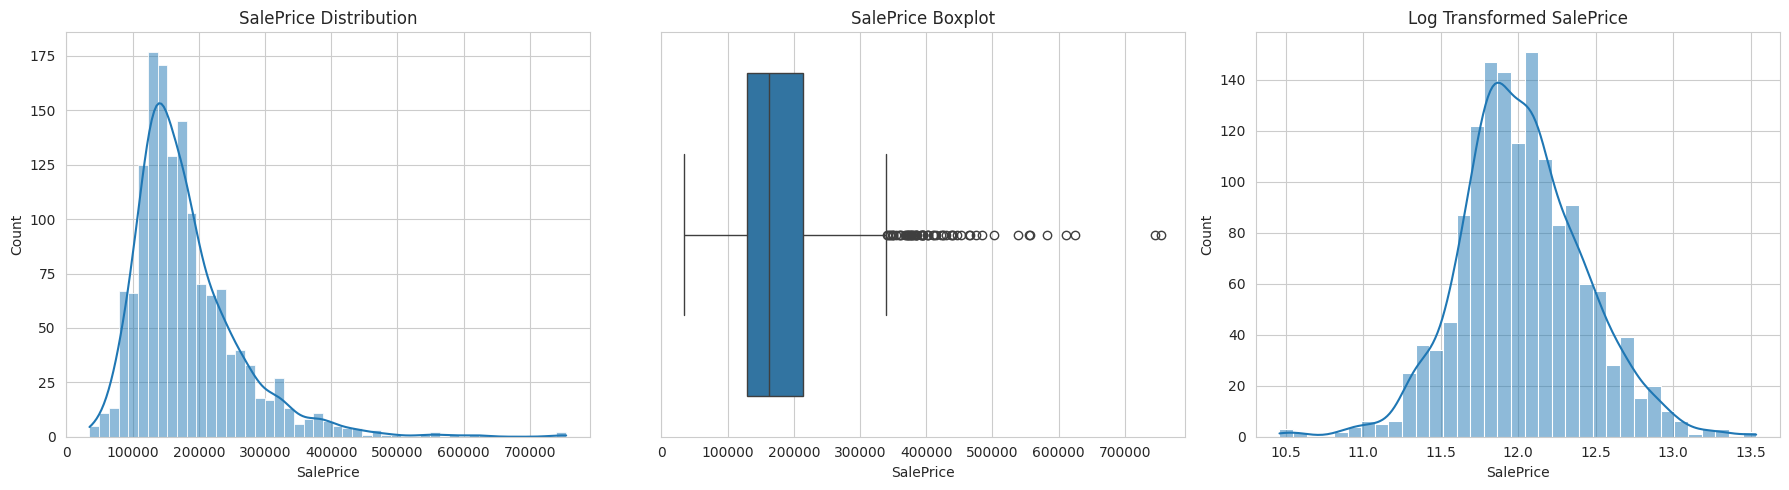

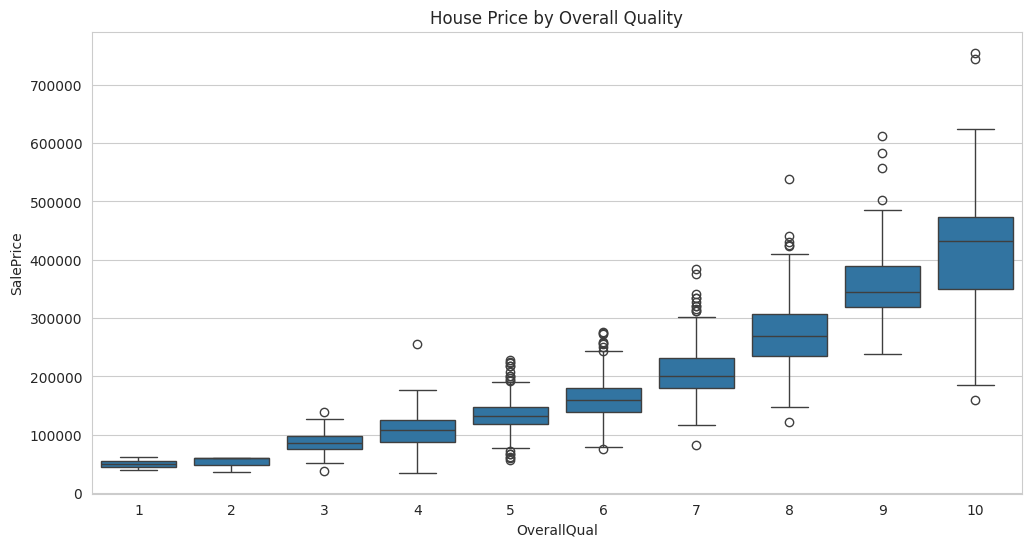

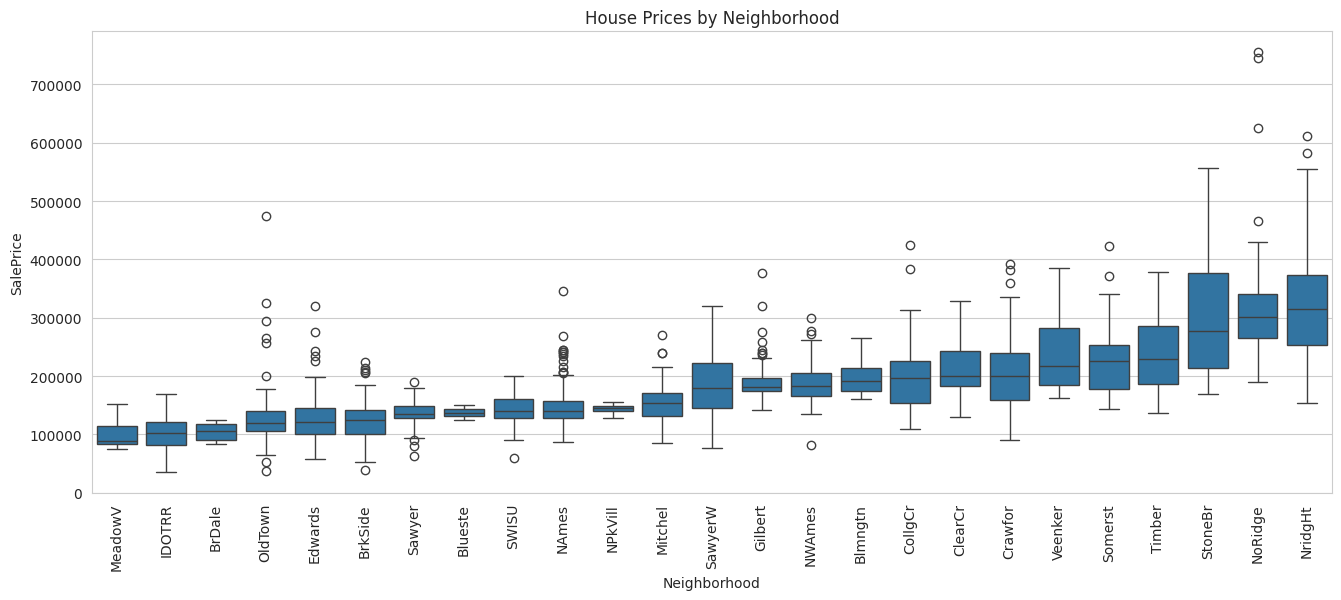

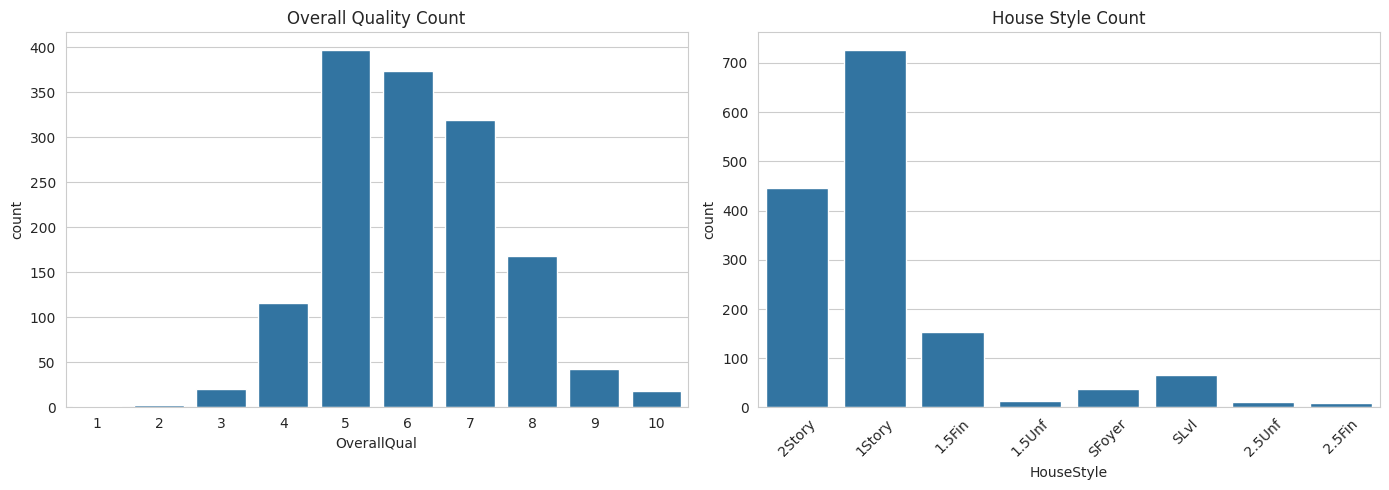

In [13]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('SalePrice Distribution')

sns.boxplot(x=df['SalePrice'], ax=axes[1])
axes[1].set_title('SalePrice Boxplot')

sns.histplot(np.log1p(df['SalePrice']), kde=True, ax=axes[2])
axes[2].set_title('Log Transformed SalePrice')

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='OverallQual', y='SalePrice')
plt.title('House Price by Overall Quality')
plt.show()

neighborhood_order = df.groupby('Neighborhood')['SalePrice'].median().sort_values().index

plt.figure(figsize=(16, 6))
sns.boxplot(data=df, x='Neighborhood', y='SalePrice', order=neighborhood_order)
plt.xticks(rotation=90)
plt.title('House Prices by Neighborhood')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x='OverallQual', ax=axes[0])
sns.countplot(data=df, x='HouseStyle', ax=axes[1])

axes[0].set_title('Overall Quality Count')
axes[1].set_title('House Style Count')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


In [16]:

# Calculate correlation and covariance
corr = df.corr(numeric_only=True)
cov = df.cov(numeric_only=True)

# Find top 10 features related to SalePrice
top_features = corr['SalePrice'].sort_values(ascending=False)

print("Top 10 features related to SalePrice:")
print(top_features.head(11))

print("\nCovariance with SalePrice:")
print(cov['SalePrice'].head(10))


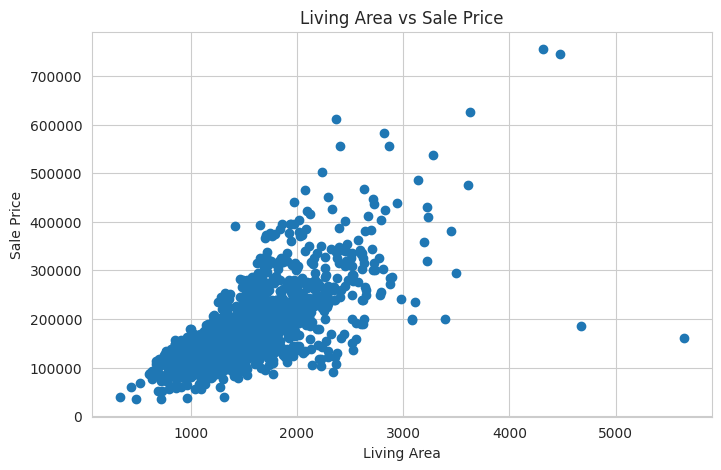

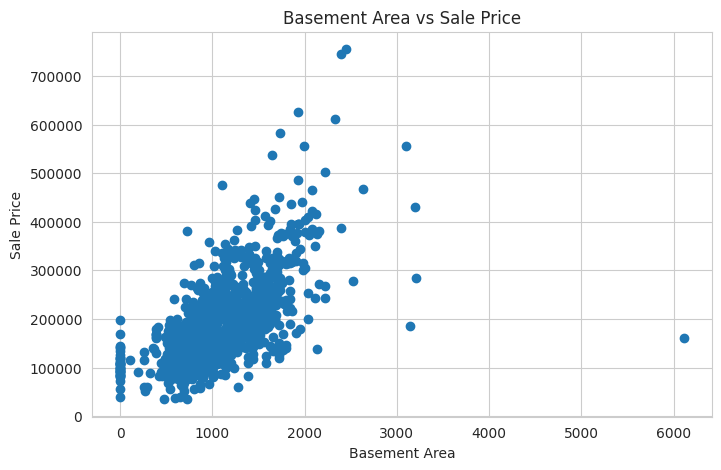

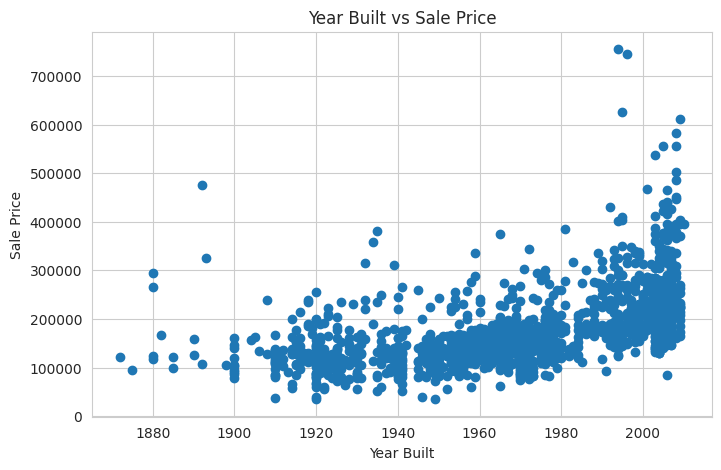

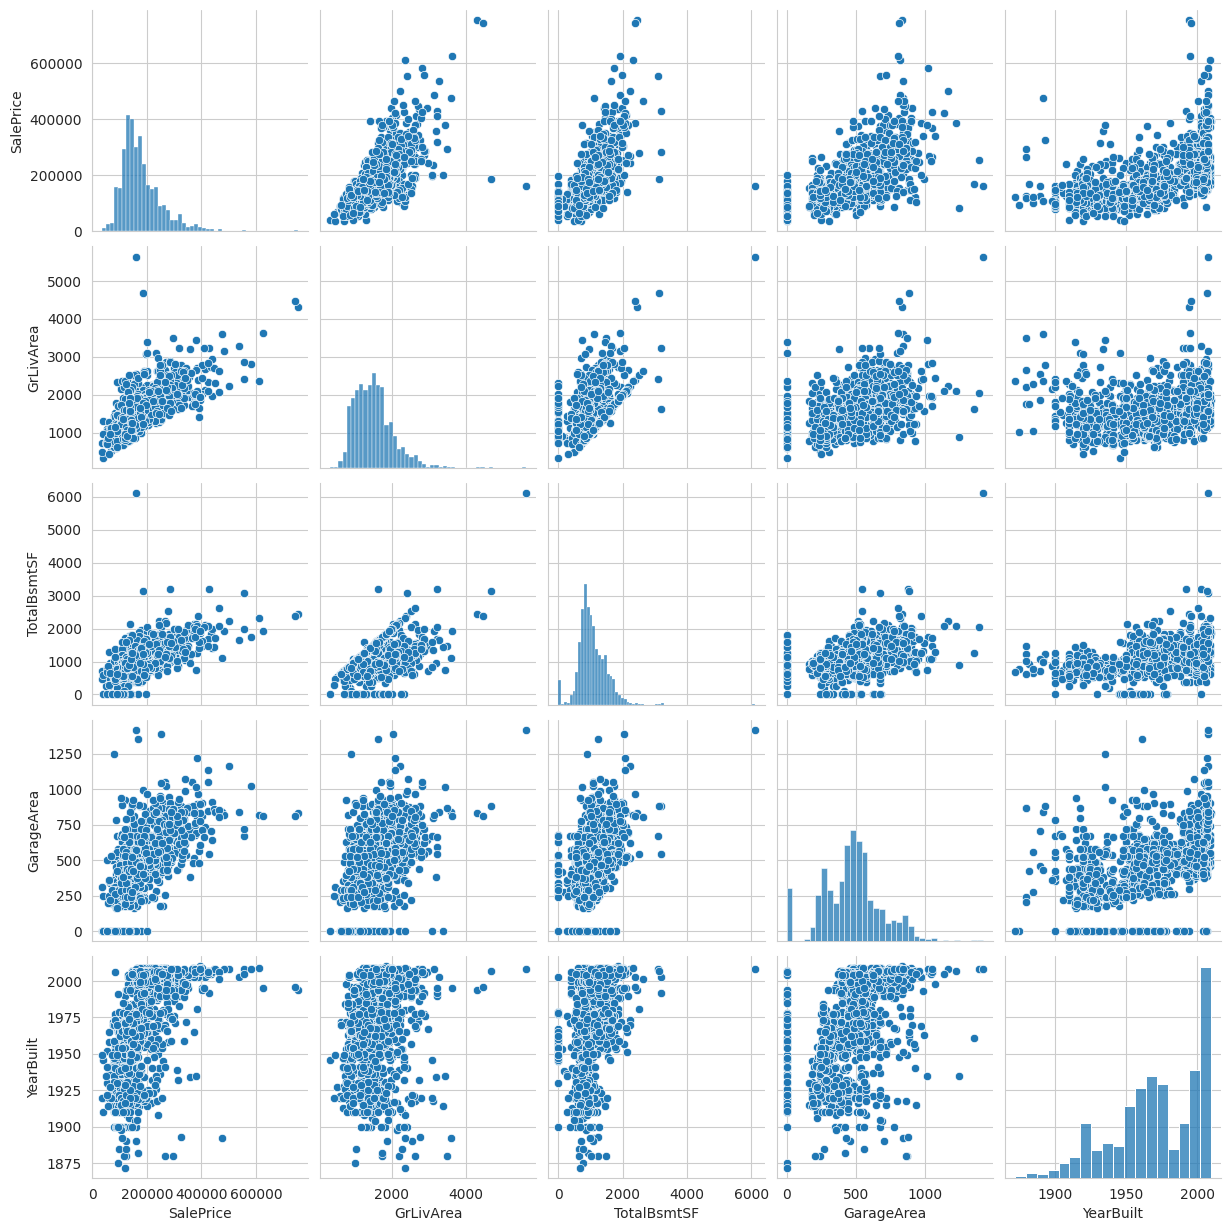

In [23]:

# Living Area vs Sale Price
plt.figure(figsize=(8, 5))
plt.scatter(df['GrLivArea'], df['SalePrice'])
plt.title('Living Area vs Sale Price')
plt.xlabel('Living Area')
plt.ylabel('Sale Price')
plt.show()

# Basement Area vs Sale Price
plt.figure(figsize=(8, 5))
plt.scatter(df['TotalBsmtSF'], df['SalePrice'])
plt.title('Basement Area vs Sale Price')
plt.xlabel('Basement Area')
plt.ylabel('Sale Price')
plt.show()

# Year Built vs Sale Price
plt.figure(figsize=(8, 5))
plt.scatter(df['YearBuilt'], df['SalePrice'])
plt.title('Year Built vs Sale Price')
plt.xlabel('Year Built')
plt.ylabel('Sale Price')
plt.show()

# Pair Plot
selected = df[['SalePrice', 'GrLivArea', 'TotalBsmtSF',
               'GarageArea', 'YearBuilt']]

sns.pairplot(selected)
plt.show()


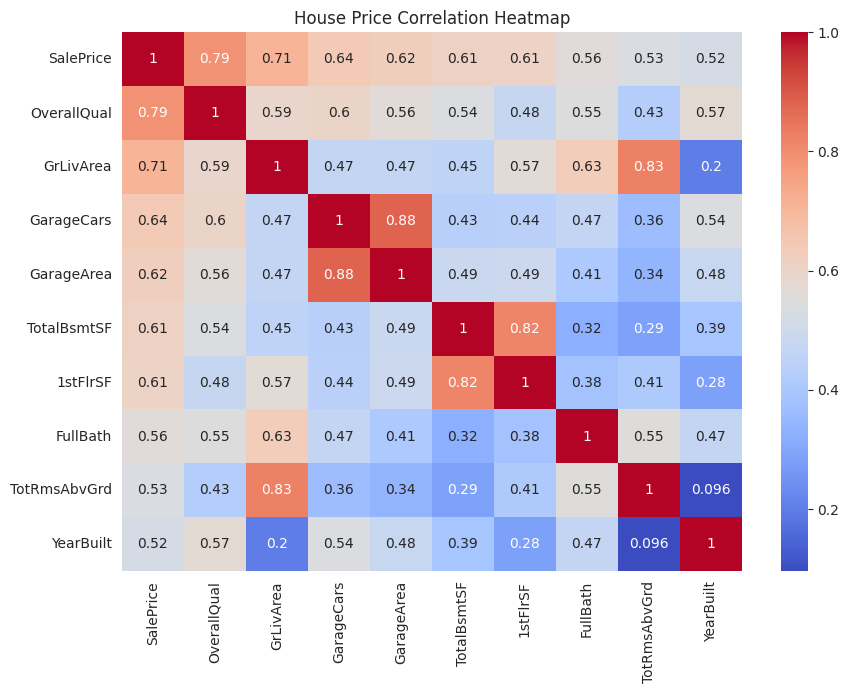

In [28]:

# Calculate correlation matrix
corr = df.select_dtypes(include='number').corr()

# Select top 10 features
top10 = corr['SalePrice'].abs().sort_values(ascending=False).head(10).index

# Create correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(corr.loc[top10, top10],
            annot=True,
            cmap='coolwarm')

plt.title('House Price Correlation Heatmap')
plt.show()

GrLivArea IQR Outliers: 31
SalePrice IQR Outliers: 61
GrLivArea Z-Score Outliers: 16
SalePrice Z-Score Outliers: 22


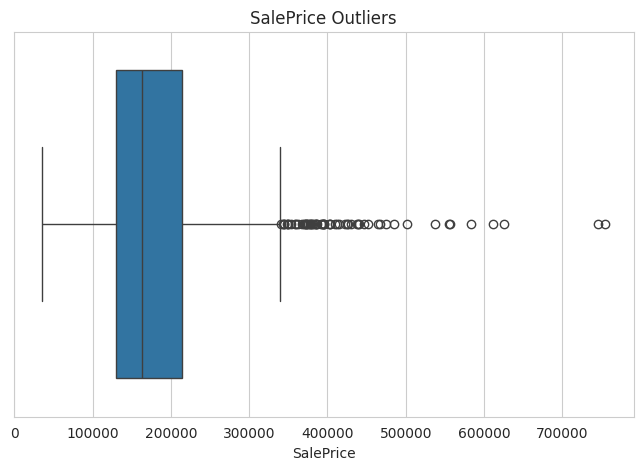

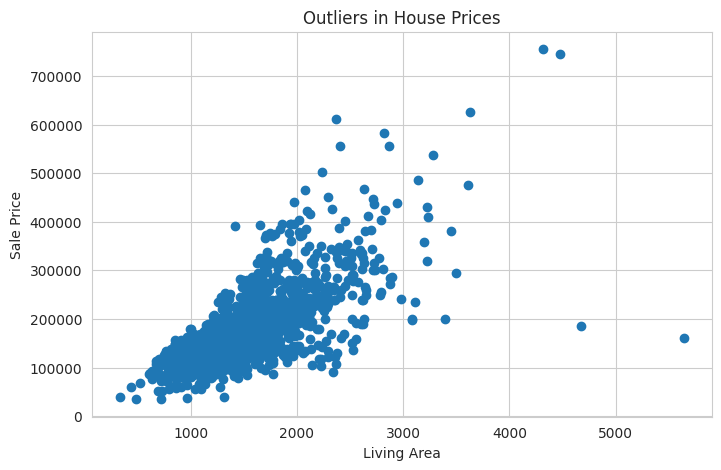

In [20]:

# Outliers using IQR method

for col in ['GrLivArea', 'SalePrice']:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, "IQR Outliers:", len(outliers))


# Outliers using Z-Score method

for col in ['GrLivArea', 'SalePrice']:

    z = (df[col] - df[col].mean()) / df[col].std()

    outliers = df[abs(z) > 3]

    print(col, "Z-Score Outliers:", len(outliers))


# Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['SalePrice'])
plt.title('SalePrice Outliers')
plt.show()


# Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(df['GrLivArea'], df['SalePrice'])
plt.title('Outliers in House Prices')
plt.xlabel('Living Area')
plt.ylabel('Sale Price')
plt.show()


In [19]:

# Check duplicate rows

print("Duplicate Rows:", df.duplicated().sum())

# Remove duplicates

df = df.drop_duplicates()

print("New Dataset Shape:", df.shape)


# Check categorical values

for col in df.select_dtypes(include='object').columns:
    print("\n", col)
    print(df[col].unique()[:10])


# Replace missing values where feature is absent

absent_cols = ['PoolQC', 'Alley', 'Fence',
               'FireplaceQu', 'GarageType']

for col in absent_cols:
    if col in df.columns:
        df[col] = df[col].fillna('None')


# Fill numerical missing values with median

for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())


# Fill remaining categorical missing values

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna(df[col].mode()[0])


# Check remaining missing values

print("\nRemaining Missing Values:")
print(df.isnull().sum().sum())

# Check impossible values

print("\nYear Built after Year Sold:")
print((df['YearBuilt'] > df['YrSold']).sum())

print("\nNegative Living Areas:")
print((df['GrLivArea'] < 0).sum())


Duplicate Rows: 0
New Dataset Shape: (1460, 81)

 MSZoning
['RL' 'RM' 'C (all)' 'FV' 'RH']

 Street
['Pave' 'Grvl']

 Alley
[nan 'Grvl' 'Pave']

 LotShape
['Reg' 'IR1' 'IR2' 'IR3']

 LandContour
['Lvl' 'Bnk' 'Low' 'HLS']

 Utilities
['AllPub' 'NoSeWa']

 LotConfig
['Inside' 'FR2' 'Corner' 'CulDSac' 'FR3']

 LandSlope
['Gtl' 'Mod' 'Sev']

 Neighborhood
['CollgCr' 'Veenker' 'Crawfor' 'NoRidge' 'Mitchel' 'Somerst' 'NWAmes'
 'OldTown' 'BrkSide' 'Sawyer']

 Condition1
['Norm' 'Feedr' 'PosN' 'Artery' 'RRAe' 'RRNn' 'RRAn' 'PosA' 'RRNe']

 Condition2
['Norm' 'Artery' 'RRNn' 'Feedr' 'PosN' 'PosA' 'RRAn' 'RRAe']

 BldgType
['1Fam' '2fmCon' 'Duplex' 'TwnhsE' 'Twnhs']

 HouseStyle
['2Story' '1Story' '1.5Fin' '1.5Unf' 'SFoyer' 'SLvl' '2.5Unf' '2.5Fin']

 RoofStyle
['Gable' 'Hip' 'Gambrel' 'Mansard' 'Flat' 'Shed']

 RoofMatl
['CompShg' 'WdShngl' 'Metal' 'WdShake' 'Membran' 'Tar&Grv' 'Roll'
 'ClyTile']

 Exterior1st
['VinylSd' 'MetalSd' 'Wd Sdng' 'HdBoard' 'BrkFace' 'WdShing' 'CemntBd'
 'Plywood' 'As

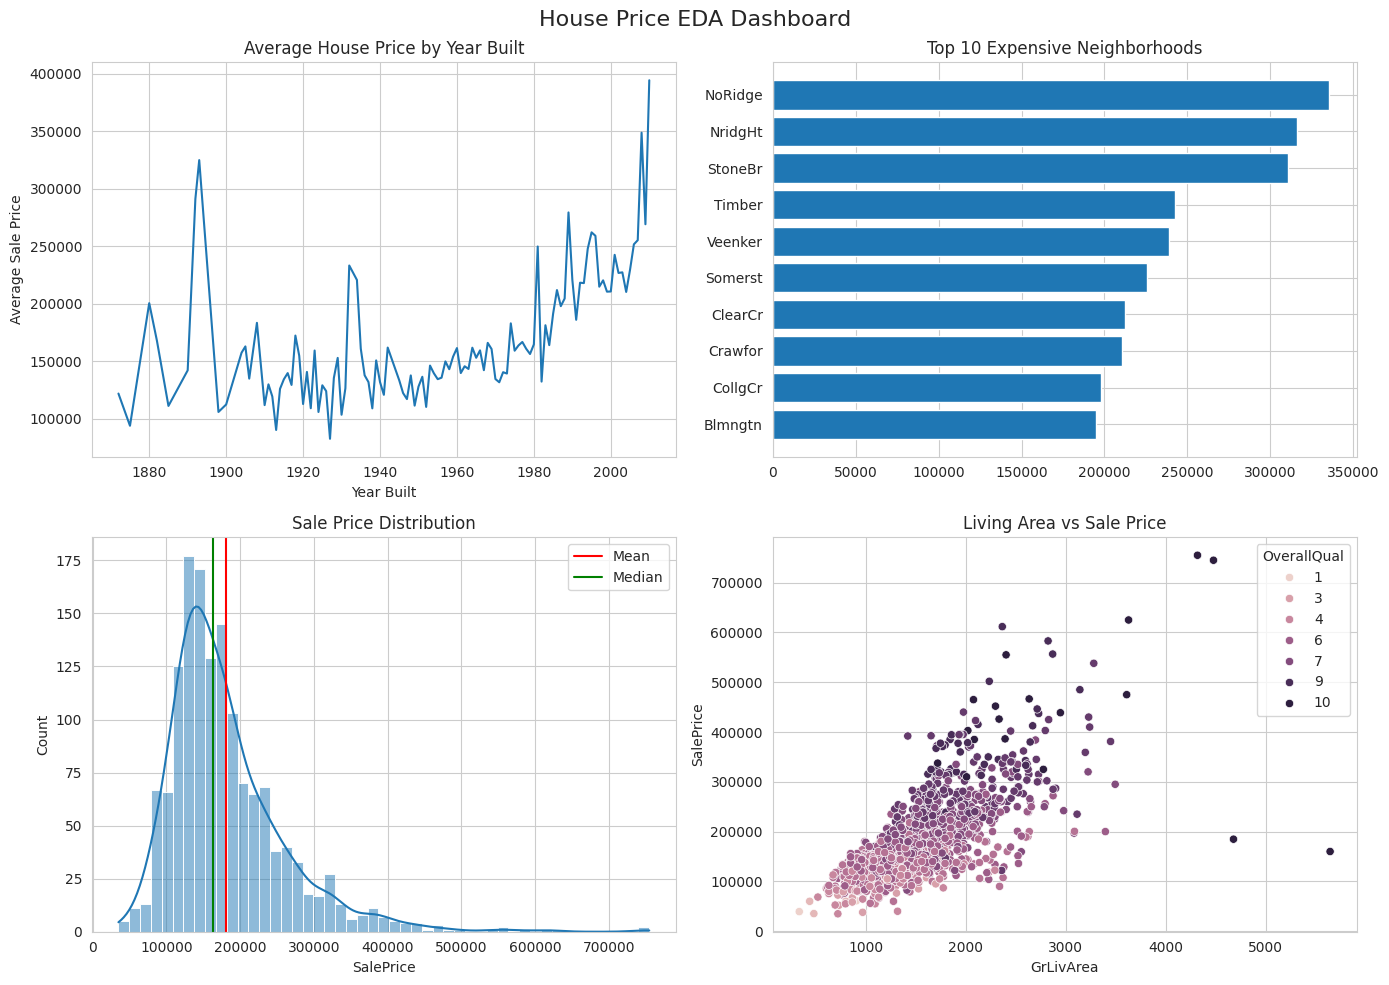

In [18]:

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Average Sale Price by Year Built

year_price = df.groupby('YearBuilt')['SalePrice'].mean()

axes[0, 0].plot(year_price.index, year_price.values)
axes[0, 0].set_title('Average House Price by Year Built')
axes[0, 0].set_xlabel('Year Built')
axes[0, 0].set_ylabel('Average Sale Price')


# 2. Top 10 Neighborhoods by Average Price

area_price = df.groupby('Neighborhood')['SalePrice'].mean()
area_price = area_price.sort_values(ascending=False).head(10)

axes[0, 1].barh(area_price.index, area_price.values)
axes[0, 1].set_title('Top 10 Expensive Neighborhoods')
axes[0, 1].invert_yaxis()


# 3. Sale Price Distribution

sns.histplot(df['SalePrice'], kde=True, ax=axes[1, 0])

axes[1, 0].axvline(df['SalePrice'].mean(),
                   color='red', label='Mean')

axes[1, 0].axvline(df['SalePrice'].median(),
                   color='green', label='Median')

axes[1, 0].set_title('Sale Price Distribution')
axes[1, 0].legend()


# 4. Living Area vs Sale Price

sns.scatterplot(data=df,
                x='GrLivArea',
                y='SalePrice',
                hue='OverallQual',
                ax=axes[1, 1])

axes[1, 1].set_title('Living Area vs Sale Price')


plt.suptitle('House Price EDA Dashboard', fontsize=16)
plt.tight_layout()

plt.savefig('eda_dashboard.png', dpi=300, bbox_inches='tight')

plt.show()



## Conclusion

1. House prices are right-skewed.
2. Overall quality has a strong relationship with house prices.
3. Larger houses generally have higher sale prices.
4. Neighborhood affects house prices.
5. Some houses contain unusual price and area values.
6. Several missing values represent features that are not available in a house.

This analysis helped us understand the factors related to house prices using Exploratory Data Analysis.
